<div style="background:linear-gradient(135deg,#0f3d6e,#1f6fb2);color:#ffffff;padding:22px 26px;border-radius:10px;margin-bottom:18px">
  <span style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;opacity:0.85">INF432 · Minería de datos para decisiones comerciales · Segundo examen</span>
  <h1 style="margin:8px 0 4px;font-size:24px;color:#ffffff">Cuaderno 02: Área 2 · Segmentación de Mercado (A2)</h1>
  <p style="margin:0;font-size:13px;opacity:0.9">Grupo: <strong>RetailAnalytics</strong> · Integrantes: Diego Fernando Banegas Bruno, Hernandez Lijeron Roly, Huanca Silvestre Grover</p>
</div>


In [1]:
# 1. IMPORTAR LIBRERÍAS Y CONFIGURACIÓN
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

SEMILLA = 1  # Semilla fija para total reproducibilidad
# Categorías de productos del dataset
productos = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']


In [2]:
# 2. CARGAR EL DATASET PREPARADO EN EL CUADERNO 00
df_limpio = pd.read_csv("data/processed/clientes_limpio.csv")
print("Datos cargados correctamente:", df_limpio.shape)


Datos cargados correctamente: (2025, 34)


# 5.2 ÁREA 2: SEGMENTACIÓN DE MERCADO (A2)

**Pregunta de negocio:** ¿Qué grupos de clientes existen según su perfil (ingreso, edad, hijos) y lo que compran (vinos, carnes, frutas, etc.), y qué estrategia comercial merece cada grupo?

- **Decisión que apoya:** qué productos, promociones y mensajes ofrecer a cada segmento.
- **Quién decide:** el gerente comercial.
- **Criterio de éxito:** encontrar entre 3 y 6 grupos con silueta mayor a 0.25, cada uno con un perfil claramente distinto en ingreso y gasto, al que se le pueda poner un nombre comercial.

**Tipo de problema:** no supervisado (agrupamiento). No hay variable de clase.

## 5.2.1 Reducción de dimensionalidad (si aplica)

*PCA: varianza explicada, número de componentes y gráfico 2D (lecciones 1.3 y 1.6-1.7). LDA o t-SNE para comparar (lecciones 1.4 y 1.5).*

# Celda de código, variables y estandarización:

In [3]:
vars_seg = ['Income', 'Edad', 'Hijos', 'MntWines', 'MntFruits', 'MntMeatProducts',
            'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']     # Perfil del cliente + qué compra
seg = df_limpio[vars_seg]                                             # Datos en unidades originales (para perfilar)
seg_s = StandardScaler().fit_transform(seg)                           # Datos estandarizados (para k-means)
print("Clientes y variables:", seg_s.shape)

Clientes y variables: (2025, 9)


# ## 5.2.1 Reducción de dimensionalidad

,PC1,PC2
Income,0.39,0.26
Edad,0.05,0.83
Hijos,-0.29,0.33
MntWines,0.35,0.29
MntFruits,0.36,-0.14
MntMeatProducts,0.40,-0.03
MntFishProducts,0.37,-0.13
MntSweetProducts,0.36,-0.13
MntGoldProds,0.28,0.03


Varianza explicada por PC1 + PC2: 60.46%


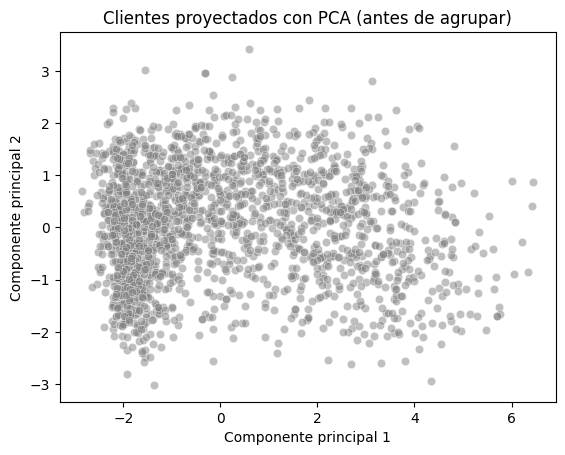

In [4]:
pca_seg = PCA(n_components=2)                                         # Reducimos a 2 dimensiones para poder graficar
seg_pca = pca_seg.fit_transform(seg_s)                                # Coordenadas de cada cliente en PC1 y PC2
print("Varianza explicada por PC1 + PC2: {:.2%}".format(pca_seg.explained_variance_ratio_.sum()))

cargas = pd.DataFrame(pca_seg.components_.T, index=vars_seg, columns=['PC1', 'PC2'])  # Peso de cada variable
display(cargas.round(2))

sns.scatterplot(x=seg_pca[:, 0], y=seg_pca[:, 1], alpha=0.5, color='gray')  # Clientes sin agrupar todavía
plt.title('Clientes proyectados con PCA (antes de agrupar)')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.show()

¿Qué observamos?

Las 2 primeras componentes explican el 60.46 % de la varianza, suficiente para visualizar los grupos en 2D.
PC1 = “poder de compra”: Income y todos los gastos (Mnt...) pesan positivo (entre 0.28 y 0.40) y Hijos pesa negativo (−0.29). A la derecha están los que más ganan y gastan, y suelen tener menos hijos.
PC2 = “etapa de vida”: lo domina la Edad (0.83), seguida de Hijos (0.33) y vinos (0.29). Arriba están los clientes mayores.
La nube es muy densa a la izquierda (mucha gente que gasta poco) y se dispersa hacia la derecha (pocos clientes que gastan mucho).

## 5.2.2 Modelado

*Si es **agrupamiento**: elección de K con la silueta (lección 2.4), segundo método (jerárquico, lección 2.3, o DBSCAN, lección 2.5) y perfil de cada grupo en unidades originales con `groupby(...).mean()`.*

*Si es **clasificación**: kNN y árbol optimizados con `GridSearchCV`, Naive Bayes, y para cada modelo la matriz de confusión y la exactitud en los datos de **prueba** (lecciones 3.3 a 3.5).*

K = 2: silueta = 0.392
K = 3: silueta = 0.268
K = 4: silueta = 0.207
K = 5: silueta = 0.210
K = 6: silueta = 0.225
K = 7: silueta = 0.229
K = 8: silueta = 0.229
K = 9: silueta = 0.230
K = 10: silueta = 0.236


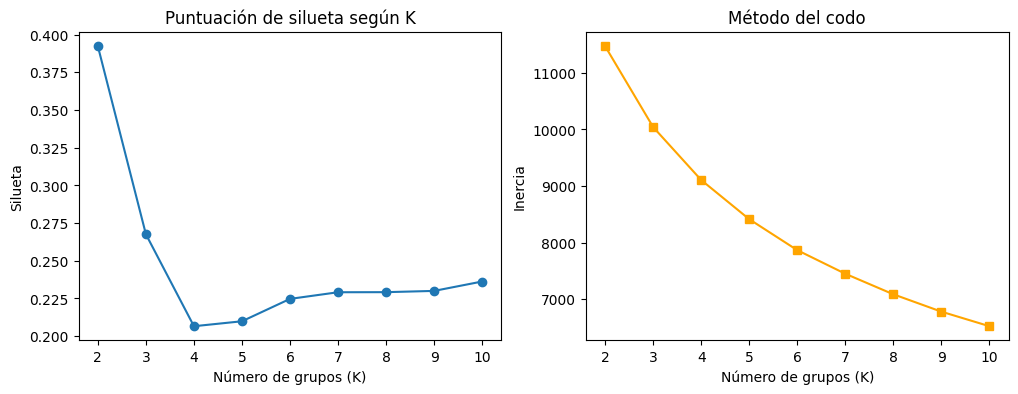

In [5]:
# k-means (5.2.2)

from sklearn.cluster import KMeans                     # Algoritmo k-means
from sklearn.metrics import silhouette_score           # Métrica de silueta

ks = range(2, 11)                                      # Valores de K a probar
siluetas, inercias = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEMILLA, init='k-means++', n_init=10)  # Modelo con K grupos
    etiquetas = km.fit_predict(seg_s)                  # Agrupa a los clientes
    siluetas.append(silhouette_score(seg_s, etiquetas))  # Qué tan bien separados quedan los grupos
    inercias.append(km.inertia_)                       # Qué tan compactos son los grupos

fig, axes = plt.subplots(1, 2, figsize=(12, 4))        # Dos gráficas lado a lado
axes[0].plot(ks, siluetas, 'o-')                       # Silueta para cada K
axes[0].set_title('Puntuación de silueta según K')
axes[0].set_xlabel('Número de grupos (K)')
axes[0].set_ylabel('Silueta')
axes[1].plot(ks, inercias, 's-', color='orange')       # Inercia para cada K (método del codo)
axes[1].set_title('Método del codo')
axes[1].set_xlabel('Número de grupos (K)')
axes[1].set_ylabel('Inercia')
plt.show()

for k, s in zip(ks, siluetas):
    print("K = {}: silueta = {:.3f}".format(k, s))     # Valores exactos para justificar la elección

¿Qué observamos? (elección de K)

La silueta más alta es K = 2 (0.392), pero dos grupos (“gastan mucho” y “gastan poco”) son demasiado generales para diseñar estrategias distintas.
K = 3 tiene la mejor silueta entre las opciones útiles para el negocio (0.268), supera el 0.25 del criterio de éxito y es claramente mejor que K = 4 a 10 (0.21 a 0.24).
En el método del codo la inercia baja fuerte de 2 a 4 y después se aplana, lo que también apoya un K pequeño.
Decisión: K = 3, justificado por la silueta y por el criterio de negocio (R4).

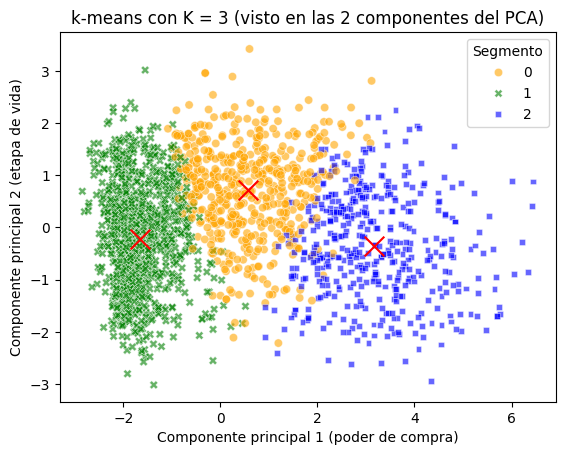

,Income,Edad,Hijos,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,Gasto_Total,Response,Clientes,% del total
Segmento,,,,,,,,,,,,,
0,63289.18,50.53,0.85,549.25,23.51,179.07,33.10,23.30,63.98,872.21,0.15,528,26.1
1,36088.15,42.57,1.29,66.88,5.36,30.76,7.48,5.43,17.20,133.10,0.10,1046,51.7
2,75849.36,44.68,0.28,573.45,77.86,472.66,111.55,82.21,81.08,1398.81,0.28,451,22.3


In [6]:
km = KMeans(n_clusters=3, random_state=SEMILLA, init='k-means++', n_init=10)  # Modelo final con K = 3
df_limpio['Segmento'] = km.fit_predict(seg_s)                  # Guarda el grupo de cada cliente
centros = pca_seg.transform(km.cluster_centers_)               # Lleva los centroides al plano del PCA

sns.scatterplot(x=seg_pca[:, 0], y=seg_pca[:, 1], hue=df_limpio['Segmento'], style=df_limpio['Segmento'],
                palette=['orange', 'green', 'blue'], alpha=0.6)            # Clientes coloreados por grupo
plt.scatter(centros[:, 0], centros[:, 1], marker='x', s=200, c='red')     # Centroides
plt.title('k-means con K = 3 (visto en las 2 componentes del PCA)')
plt.xlabel('Componente principal 1 (poder de compra)')
plt.ylabel('Componente principal 2 (etapa de vida)')
plt.show()

perfil = df_limpio.groupby('Segmento')[vars_seg + ['Gasto_Total', 'Response']].mean().round(2)  # Promedios en unidades ORIGINALES
perfil['Clientes'] = df_limpio['Segmento'].value_counts().sort_index()    # Tamaño de cada grupo
perfil['% del total'] = (perfil['Clientes'] / len(df_limpio) * 100).round(1)
perfil

Silueta k-means    (K=3): 0.268
Silueta jerárquico (K=3): 0.178


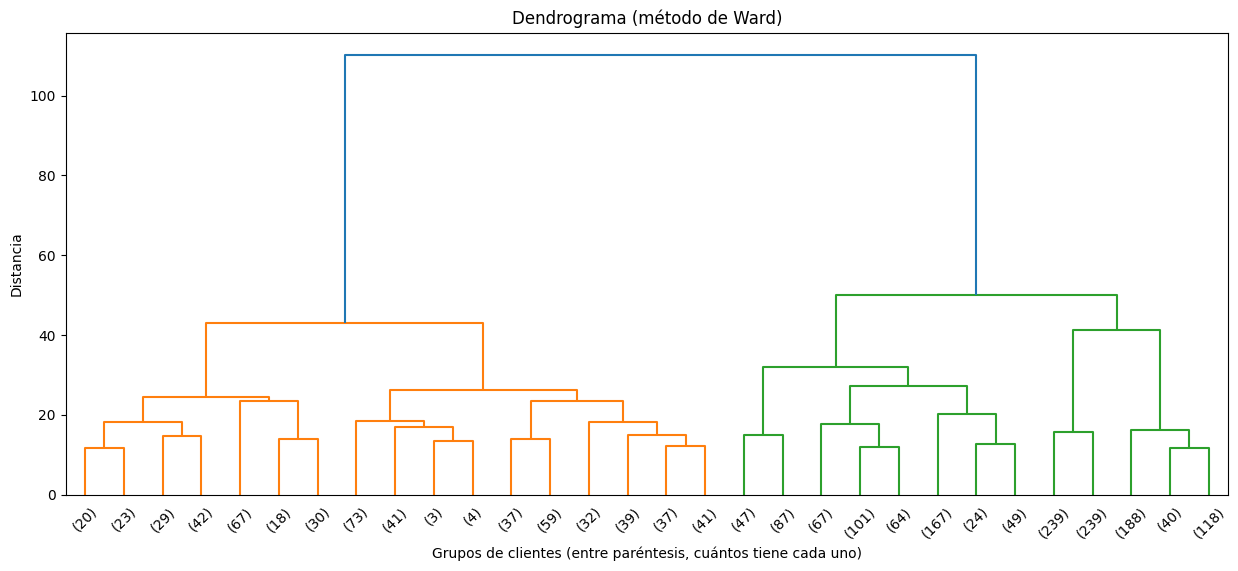

Jerárquico,0,1,2
k-means,,,
0,172,344,12
1,1,233,812
2,422,29,0


In [7]:
# jerárquico (lo exige R4)

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster   # Agrupamiento jerárquico

hc = linkage(seg_s, method='ward', metric='euclidean')               # Une clientes paso a paso (método de Ward)
plt.figure(figsize=(15, 6))
dendrogram(hc, truncate_mode='lastp', p=30, leaf_font_size=10)       # Muestra solo las últimas 30 uniones para que se lea
plt.title('Dendrograma (método de Ward)')
plt.xlabel('Grupos de clientes (entre paréntesis, cuántos tiene cada uno)')
plt.ylabel('Distancia')
plt.show()

df_limpio['Jerarquico'] = fcluster(hc, t=3, criterion='maxclust') - 1   # Corta el árbol en 3 grupos (0, 1, 2)
print('Silueta k-means    (K=3): {:.3f}'.format(silhouette_score(seg_s, df_limpio['Segmento'])))
print('Silueta jerárquico (K=3): {:.3f}'.format(silhouette_score(seg_s, df_limpio['Jerarquico'])))
pd.crosstab(df_limpio['Segmento'], df_limpio['Jerarquico'],
            rownames=['k-means'], colnames=['Jerárquico'])            # ¿Coinciden los dos métodos?

¿Qué observamos? (k-means vs jerárquico)

En el dendrograma, el salto más grande (distancia ≈ 110) separa a los clientes en 2 grandes bloques. Eso coincide con la silueta, que también era máxima en K = 2. Al cortar más abajo (≈ 45-50) aparecen 3 grupos.
k-means separa mejor: silueta de 0.268 contra 0.178 del jerárquico.
Los dos métodos coinciden en el 78 % de los clientes (422 + 344 + 812 de 2025). Los grupos de los extremos son muy estables: el 94 % del grupo premium de k-means (422 de 451) también queda junto en el jerárquico, y el 78 % del grupo de bajo gasto (812 de 1046) también.
La diferencia está en el grupo intermedio (k-means 0): el jerárquico lo reparte entre sus vecinos.
Conclusión: nos quedamos con k-means, porque tiene mejor silueta y grupos más equilibrados. Que el jerárquico confirme los extremos demuestra que los segmentos son reales y no dependen del algoritmo.

Segmento,Adultos amantes del vino,Familias de presupuesto ajustado,Premium sin hijos
Income,63289.18,36088.15,75849.36
Edad,50.53,42.57,44.68
Hijos,0.85,1.29,0.28
MntWines,549.25,66.88,573.45
MntFruits,23.51,5.36,77.86
MntMeatProducts,179.07,30.76,472.66
MntFishProducts,33.10,7.48,111.55
MntSweetProducts,23.30,5.43,82.21
MntGoldProds,63.98,17.20,81.08
Gasto_Total,872.21,133.10,1398.81


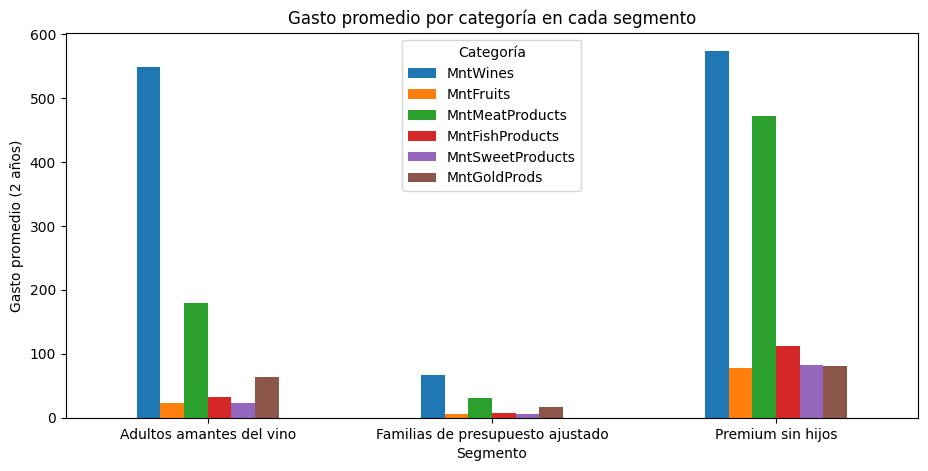

In [8]:
nombres = {0: 'Adultos amantes del vino', 1: 'Familias de presupuesto ajustado', 2: 'Premium sin hijos'}  # Nombre comercial de cada grupo
df_limpio['Nombre_Segmento'] = df_limpio['Segmento'].map(nombres)     # Agrega el nombre a cada cliente
perfil.index = perfil.index.map(nombres)                               # Pone los nombres en la tabla de perfiles
display(perfil.T)                                                      # Tabla completa (volteada para que se lea)

gasto_cat = df_limpio.groupby('Nombre_Segmento')[productos].mean()     # Gasto promedio por categoría en cada grupo
gasto_cat.plot(kind='bar', figsize=(11, 5))                            # Barras agrupadas
plt.title('Gasto promedio por categoría en cada segmento')
plt.xlabel('Segmento')
plt.ylabel('Gasto promedio (2 años)')
plt.xticks(rotation=0)                                                 # Nombres horizontales
plt.legend(title='Categoría')
plt.show()

¿Qué observamos? (perfil de los segmentos)

Segmento	Clientes	Ingreso	Hijos	Gasto total	Acepta campañas	% de las ventas
Premium sin hijos	451 (22 %)	75 849	0.28	1 399	28 %	51 %
Adultos amantes del vino	528 (26 %)	63 289	0.85	872	15 %	37 %
Familias de presupuesto ajustado	1046 (52 %)	36 088	1.29	133	10 %	11 %
Premium sin hijos: el mayor ingreso, casi sin hijos y gasto alto en todas las categorías, sobre todo carnes (473) y vinos (573). Es el que más acepta campañas (28 %).
Adultos amantes del vino: los mayores (50 años) e ingreso medio-alto. Gastan casi lo mismo en vino que los premium (549), pero mucho menos en lo demás.
Familias de presupuesto ajustado: la mitad de la base, con el menor ingreso y más hijos. Gastan poco en todo y responden poco a las campañas.

## 5.2.3 Interpretación para el negocio

*¿Qué responde este resultado a la pregunta de negocio? ¿Qué decisión recomiendan? ¿Qué error es más costoso?*

Respuesta a la pregunta: la base de clientes se divide en 3 segmentos con perfiles muy distintos. Se cumple el criterio de éxito: 3 grupos, silueta de 0.268 (> 0.25) y un nombre comercial para cada uno.

Estrategia por segmento:

Premium sin hijos (retener y fidelizar): generan la mitad de las ventas. Conviene un programa de fidelidad, productos gourmet (carnes y pescados premium) y acceso anticipado a promociones. Son la prioridad de las campañas, porque aceptan casi el doble del promedio.
Adultos amantes del vino (venta cruzada): ya compran mucho vino. La oportunidad es ofrecerles combos de vino + carnes, quesos o dulces para subir su gasto en las otras categorías.
Familias de presupuesto ajustado (volumen con descuento): son muchos pero gastan poco. No conviene gastar en llamadas para ellos (aceptan solo el 10 %). Mejor comunicación de bajo costo (correo, web) con promociones familiares y descuentos en productos básicos.

Despliegue: cada cliente nuevo se asigna a su segmento con km.predict() (con los mismos datos estandarizados), y el CRM muestra su etiqueta para que marketing elija la oferta adecuada.

Monitoreo: recalcular los segmentos cada 6 meses y revisar si cambia el tamaño de cada grupo, por ejemplo si familias pasan a premium o al revés.

Limitaciones: la silueta (0.268) indica grupos con cierta superposición en la zona intermedia; los datos son de hace unos 10 años.